# SmartMentor · Métricas de la cohorte 1

Cuaderno reproducible de arriba abajo que calcula **todas las métricas del brief** (sección
«Métricas y evaluación») con las funciones puras de `ai/app/domain/metrics.py`. La definición,
la fórmula, la tabla de origen y el umbral de cada métrica están en `docs/evaluation/metrics.md`.

**Modos de ejecución**

| Modo | Cuándo | Cómo |
| --- | --- | --- |
| `database` | Cohorte real | Definir `METRICS_DATABASE_URL` en el entorno con un usuario **de solo lectura**. La URL nunca se escribe en el cuaderno. |
| `synthetic` | Demostración y CI | Sin `METRICS_DATABASE_URL` (o con `FORCE_SYNTHETIC = True`). Datos inventados con semilla fija de `synthetic_data.py`. |

Con datos sintéticos **los números no son resultados del piloto**: solo comprueban que el cálculo
y los gráficos funcionan. Antes de publicar un cuaderno ejecutado contra la base real, revise que
sus salidas solo contengan agregados (este cuaderno nunca imprime filas individuales).

In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Raíz del repositorio: la carpeta (hacia arriba desde donde corre el cuaderno) que tiene ai/ y notebooks/.
ROOT = next(
    p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
    if (p / "ai" / "app" / "domain" / "metrics.py").exists()
)
sys.path.insert(0, str(ROOT / "ai"))
sys.path.insert(0, str(ROOT / "notebooks"))

from app.domain import metrics as m  # noqa: E402  (funciones puras, solo biblioteca estándar)
import metrics_data  # noqa: E402

# --- Parámetros (cambiar aquí y solo aquí) ---------------------------------------------------
FORCE_SYNTHETIC = False   # True: ignora METRICS_DATABASE_URL y usa datos sintéticos
SEED = 20260507           # semilla de los datos sintéticos y del bootstrap
N_BOOTSTRAP = 2000        # remuestreos para el IC del d de Cohen
QWK_LEVELS = 4            # el puntaje 0-100 se redondea a 0..QWK_LEVELS (4 -> pasos de 25)
PASS_SCORE = 70           # umbral de aprobación de un tema (brief)
MASTERY_LEVEL = 0.8       # nivel de dominio (brief)
SHOW_RAGAS = False        # RAGAS completo exige un LLM y red: se deja apagado por defecto

plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 120)

In [2]:
frames, MODE = metrics_data.load(prefer_database=not FORCE_SYNTHETIC, seed=SEED)
if MODE == "synthetic":
    print("MODO DEMOSTRACIÓN: datos sintéticos (semilla %d). No son resultados del piloto." % SEED)
else:
    print("MODO BASE DE DATOS: solo lectura. Las salidas siguientes son agregados.")
print({name: len(frame) for name, frame in frames.items()})

enrollments = frames["enrollments"]
path_steps = frames["path_steps"]
print("Inscripciones analizadas:", len(enrollments),
      "| por brazo:", enrollments["pilot_arm"].value_counts(dropna=False).to_dict())

MODO DEMOSTRACIÓN: datos sintéticos (semilla 20260507). No son resultados del piloto.
{'syllabus_sets': 23, 'item_annotations': 160, 'item_responses': 670, 'grading_pairs': 60, 'video_judgments': 60, 'enrollments': 24, 'path_steps': 120, 'learning_gain': 22, 'surveys': 22, 'llm_calls': 400, 'resources': 40}
Inscripciones analizadas: 24 | por brazo: {'personalized': 12, 'fixed': 12}


In [3]:
# Tablero final: cada métrica se registra una vez con su meta del brief.
scorecard: list[dict[str, object]] = []


def record(dimension: str, metric: str, value: float | None, n: int, goal: str, met: bool | None) -> None:
    scorecard.append({"dimension": dimension, "metric": metric,
                      "value": None if value is None else round(float(value), 3),
                      "n": n, "goal": goal,
                      "met": "reportar" if met is None else ("sí" if bool(met) else "no")})

## 1. Estructuración del syllabus: F1 de temas y prerrequisitos

Fuente: `syllabus_extractions` (salida de la IA) frente a los temas finales del instructor. Meta: F1 ≥ 0,85.

,conjunto,precisión,recall,F1,n_final
0,Temas,0.833,0.833,0.833,6
1,Prerrequisitos,0.833,1.000,0.909,5


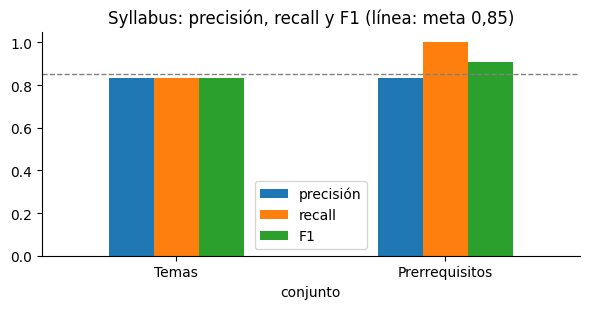

In [4]:
syllabus = frames["syllabus_sets"]
rows = []
for kind, label in (("topic", "Temas"), ("prerequisite", "Prerrequisitos")):
    sub = syllabus[syllabus["kind"] == kind]
    predicted = {(r.course_id, r.key) for r in sub[sub["side"] == "predicted"].itertuples()}
    final = {(r.course_id, r.key) for r in sub[sub["side"] == "final"].itertuples()}
    s = m.set_f1(predicted, final)
    rows.append({"conjunto": label, "precisión": s.precision, "recall": s.recall, "F1": s.f1,
                 "n_final": len(final)})
    record("Syllabus", f"F1 de {label.lower()}", s.f1, len(final), "F1 ≥ 0,85", s.f1 >= 0.85)
syllabus_table = pd.DataFrame(rows).round(3)
display(syllabus_table)
ax = syllabus_table.set_index("conjunto")[["precisión", "recall", "F1"]].plot.bar(rot=0, figsize=(6, 3.2))
ax.axhline(0.85, color="grey", ls="--", lw=1)
ax.set_ylim(0, 1.05); ax.set_title("Syllabus: precisión, recall y F1 (línea: meta 0,85)")
plt.tight_layout(); plt.show()

## 2. Calidad de preguntas: % válidas y kappa de Cohen

Fuente: `item_annotations` (2 expertos por ítem). Un ítem es válido solo si **ambos** lo marcan válido. Meta: ≥ 80 % válidas y κ ≥ 0,6.

Ítems anotados por 2 expertos: 80 | válidos: 71.2 % | κ veredicto: 0.726


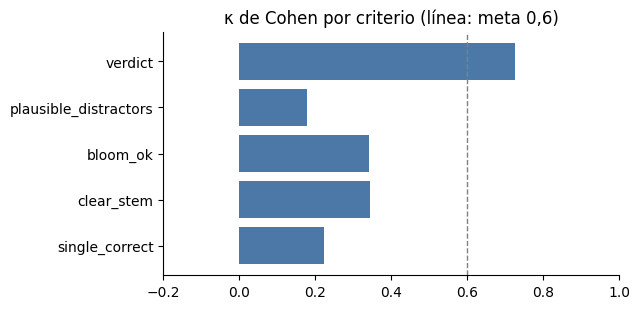

In [5]:
ann = frames["item_annotations"]
wide = ann.pivot(index="assessment_item_id", columns="evaluator_slot")
complete = wide.dropna(subset=[("verdict", 1), ("verdict", 2)])
verdicts_by_item = [[a == "valid", b == "valid"]
                    for a, b in zip(complete[("verdict", 1)], complete[("verdict", 2)])]
valid_pct = m.valid_question_rate(verdicts_by_item)
kappa_verdict = m.cohen_kappa(list(complete[("verdict", 1)]), list(complete[("verdict", 2)]))
n_items = len(complete)
record("Calidad de preguntas", "% de preguntas válidas", valid_pct, n_items, "≥ 80 %", valid_pct >= 80)
record("Calidad de preguntas", "κ de Cohen (veredicto)", kappa_verdict, n_items, "κ ≥ 0,6", kappa_verdict >= 0.6)

criteria = ["single_correct", "clear_stem", "bloom_ok", "plausible_distractors", "verdict"]
kappas = {c: m.cohen_kappa(list(complete[(c, 1)]), list(complete[(c, 2)])) for c in criteria}
print(f"Ítems anotados por 2 expertos: {n_items} | válidos: {valid_pct:.1f} % | κ veredicto: {kappa_verdict:.3f}")
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.barh(list(kappas), list(kappas.values()), color="#4c78a8")
ax.axvline(0.6, color="grey", ls="--", lw=1)
ax.set_xlim(-0.2, 1.0); ax.set_title("κ de Cohen por criterio (línea: meta 0,6)")
plt.tight_layout(); plt.show()

## 3. Psicometría de ítems: dificultad y discriminación

Fuente: `attempt_answers` del piloto. Discriminación = correlación punto-biserial entre acertar el ítem y el puntaje total del intento sin ese ítem. Meta: discriminación ≥ 0,2. Se exige un mínimo de respuestas por ítem para no reportar ruido.

Ítems con ≥ 10 respuestas: 24 | con discriminación ≥ 0,2: 45.8 %


,difficulty,discrimination
count,24.000,24.000
mean,0.484,0.162
std,0.206,0.319
min,0.091,-0.354
25%,0.325,-0.056
50%,0.500,0.094
75%,0.652,0.351
max,0.846,0.813


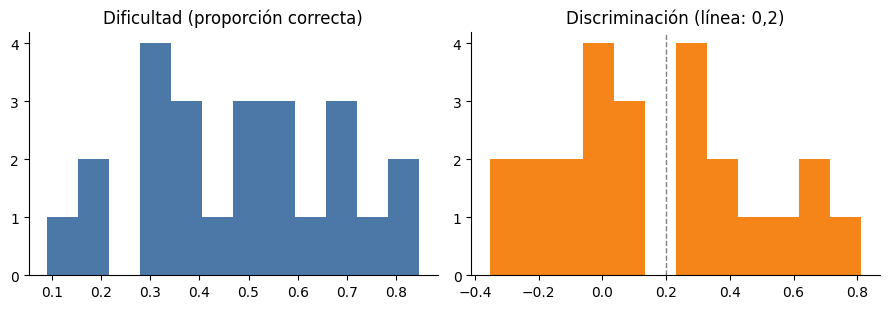

In [6]:
MIN_RESPONSES = 10
resp = frames["item_responses"].copy()
resp["total"] = resp.groupby("attempt_id")["is_correct"].transform("sum")
item_rows = []
for item_id, g in resp.groupby("assessment_item_id"):
    if len(g) < MIN_RESPONSES:
        continue
    item_rows.append({
        "item": item_id, "n": len(g),
        "difficulty": m.item_difficulty(list(g["is_correct"])),
        "discrimination": m.item_discrimination(list(g["is_correct"]), list(g["total"])),
    })
items_stats = pd.DataFrame(item_rows)
ok_share = float((items_stats["discrimination"] >= 0.2).mean()) if len(items_stats) else float("nan")
print(f"Ítems con ≥ {MIN_RESPONSES} respuestas: {len(items_stats)} | con discriminación ≥ 0,2: {100 * ok_share:.1f} %")
display(items_stats[["difficulty", "discrimination"]].describe().round(3))
record("Psicometría", "% de ítems con discriminación ≥ 0,2", 100 * ok_share, len(items_stats),
       "discriminación ≥ 0,2", None)
record("Psicometría", "Discriminación mediana", float(items_stats["discrimination"].median()),
       len(items_stats), "≥ 0,2", float(items_stats["discrimination"].median()) >= 0.2)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
axes[0].hist(items_stats["difficulty"], bins=12, color="#4c78a8"); axes[0].set_title("Dificultad (proporción correcta)")
axes[1].hist(items_stats["discrimination"], bins=12, color="#f58518")
axes[1].axvline(0.2, color="grey", ls="--", lw=1); axes[1].set_title("Discriminación (línea: 0,2)")
plt.tight_layout(); plt.show()

## 4. Texto generado (RAG): fidelidad

Fuente: `resources.faithfulness` (verificador por afirmaciones de `content.check_faithfulness`). Meta: fidelidad ≥ 0,8. RAGAS completo (relevancia de la respuesta y precisión del contexto) necesita un LLM y red; se activa con `SHOW_RAGAS = True` en un entorno que los tenga, sobre una muestra pequeña.

Recursos evaluados: 40 | fidelidad media 0.887 | mínimo 0.710 | recursos bajo 0,8: 5


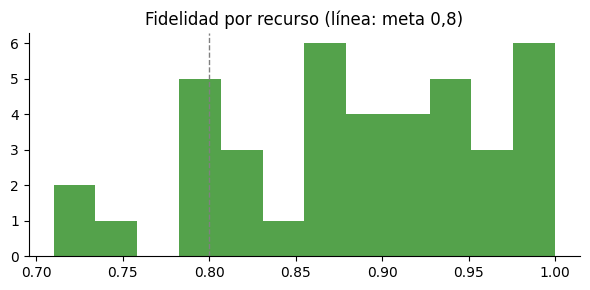

In [7]:
faith = frames["resources"]["faithfulness"].astype(float)
record("Texto generado (RAG)", "Fidelidad media", faith.mean(), len(faith), "≥ 0,8", faith.mean() >= 0.8)
print(f"Recursos evaluados: {len(faith)} | fidelidad media {faith.mean():.3f} | "
      f"mínimo {faith.min():.3f} | recursos bajo 0,8: {(faith < 0.8).sum()}")
fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(faith, bins=12, color="#54a24b"); ax.axvline(0.8, color="grey", ls="--", lw=1)
ax.set_title("Fidelidad por recurso (línea: meta 0,8)")
plt.tight_layout(); plt.show()
if SHOW_RAGAS:
    raise NotImplementedError("Ejecute RAGAS fuera del cuaderno y registre sus medias con record().")

## 5. Recomendación de videos: Precision@3 y nDCG@3

Fuente: `video_relevance_judgments` sobre los candidatos de `video_candidates` ordenados por `rank`. La relevancia binaria de un candidato es «la mayoría de los jueces lo marca pertinente» (empate cuenta como pertinente); para nDCG se usa la proporción de jueces (relevancia graduada). Meta: P@3 ≥ 0,7. Línea base honesta: azar (orden aleatorio, valor esperado).

,topic,candidates,P@3,nDCG@3,P@3 azar
0,t_conditionals,6,1.000,0.852,0.833
1,t_data_structures,6,0.667,1.000,0.333
2,t_functions,6,0.667,0.867,0.667
3,t_loops,6,1.000,1.000,0.833
4,t_variables,6,0.667,0.840,0.500


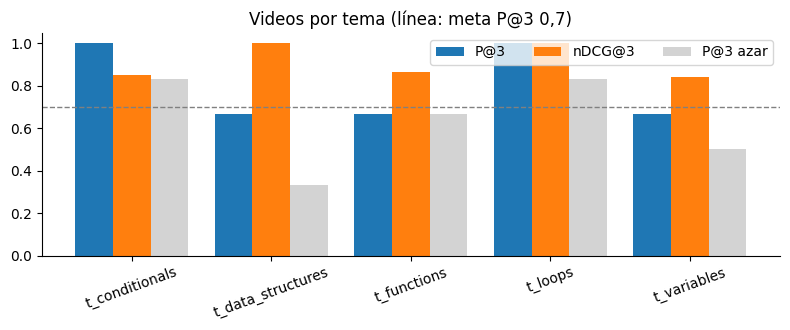

In [8]:
vj = frames["video_judgments"]
cand = (vj.groupby(["topic_id", "video_candidate_id", "rank"], as_index=False)["is_relevant"].mean()
          .rename(columns={"is_relevant": "agree"}))
rows = []
for topic, g in cand.groupby("topic_id"):
    g = g.sort_values("rank")
    binary = [int(a >= 0.5) for a in g["agree"]]
    graded = list(g["agree"])
    rows.append({"topic": topic, "candidates": len(g),
                 "P@3": m.precision_at_k(binary, 3),
                 "nDCG@3": m.ndcg_at_k(graded, 3),
                 "P@3 azar": float(np.mean(binary))})
video_table = pd.DataFrame(rows)
p3, ndcg3 = video_table["P@3"].mean(), video_table["nDCG@3"].mean()
record("Recomendación de videos", "Precision@3 (media por tema)", p3, len(video_table), "P@3 ≥ 0,7", p3 >= 0.7)
record("Recomendación de videos", "nDCG@3 (media por tema)", ndcg3, len(video_table), "reportar", None)
display(video_table.round(3))
x = np.arange(len(video_table)); w = 0.27
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.bar(x - w, video_table["P@3"], w, label="P@3"); ax.bar(x, video_table["nDCG@3"], w, label="nDCG@3")
ax.bar(x + w, video_table["P@3 azar"], w, label="P@3 azar", color="lightgrey")
ax.axhline(0.7, color="grey", ls="--", lw=1)
ax.set_xticks(x); ax.set_xticklabels(video_table["topic"], rotation=20); ax.legend(ncol=3)
ax.set_title("Videos por tema (línea: meta P@3 0,7)")
plt.tight_layout(); plt.show()

## 6. Calificación automática: QWK (LLM frente a humano)

Fuente: `human_gradings` (muestra aleatoria y solicitudes del aprendiz) frente a `attempt_answers.score` del juez LLM. Los puntajes 0–100 se redondean a `QWK_LEVELS` niveles ordinales. Meta: QWK ≥ 0,6. Se reporta aparte la muestra aleatoria (la que vale para la métrica) y la de solicitudes del aprendiz (sesgada hacia desacuerdos).

,muestra,n,QWK,acuerdo exacto
0,random,48,0.846,0.688
1,learner_request,12,0.915,0.833
2,todas,60,0.860,0.717


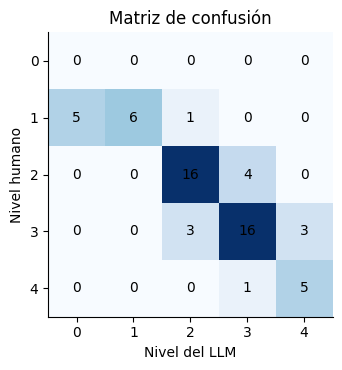

In [9]:
gp = frames["grading_pairs"].copy()
to_level = lambda s: int(round(float(s) / 100 * QWK_LEVELS))
gp["llm_level"] = gp["llm_score"].map(to_level)
gp["human_level"] = gp["human_score"].map(to_level)
qwk_rows = []
for label, sub in (("random", gp[gp["sample_type"] == "random"]), ("learner_request", gp[gp["sample_type"] == "learner_request"]), ("todas", gp)):
    if len(sub) >= 2:
        qwk_rows.append({"muestra": label, "n": len(sub),
                         "QWK": m.quadratic_weighted_kappa(list(sub["llm_level"]), list(sub["human_level"]), 0, QWK_LEVELS),
                         "acuerdo exacto": float((sub["llm_level"] == sub["human_level"]).mean())})
qwk_table = pd.DataFrame(qwk_rows).round(3)
display(qwk_table)
main = qwk_table[qwk_table["muestra"] == "random"].iloc[0]
record("Calificación automática", "QWK (muestra aleatoria)", main["QWK"], int(main["n"]), "QWK ≥ 0,6", main["QWK"] >= 0.6)
conf = pd.crosstab(gp["human_level"], gp["llm_level"]).reindex(index=range(QWK_LEVELS + 1), columns=range(QWK_LEVELS + 1), fill_value=0)
fig, ax = plt.subplots(figsize=(4.2, 3.8))
im = ax.imshow(conf.values, cmap="Blues")
for (i, j), v in np.ndenumerate(conf.values):
    ax.text(j, i, v, ha="center", va="center")
ax.set_xlabel("Nivel del LLM"); ax.set_ylabel("Nivel humano"); ax.set_title("Matriz de confusión")
plt.tight_layout(); plt.show()

## 7. Validez del diagnóstico: AUC-ROC

Fuente: `diagnostics.level_by_topic` (nivel estimado por tema) frente a si la persona aprobó el quiz del tema al **primer intento** (`path_steps`). Solo temas que la persona intentó. Meta: AUC ≥ 0,7.

Pares (persona, tema): 108 | AUC = 0.898


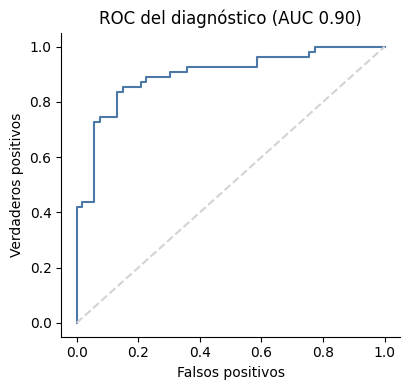

In [10]:
d = path_steps.dropna(subset=["diagnostic_level", "first_attempt_passed"])
d = d[d["attempts_used"] > 0]
labels = [bool(v) for v in d["first_attempt_passed"]]
scores = [float(v) for v in d["diagnostic_level"]]
if len(set(labels)) == 2:
    auc = m.auc_roc(scores, labels)
else:
    auc = None
    print("El AUC no se puede calcular: falta una de las dos clases.")
record("Validez del diagnóstico", "AUC-ROC", auc, len(d), "AUC ≥ 0,7", None if auc is None else auc >= 0.7)
if auc is not None:
    # Curva ROC con los mismos datos (solo para el gráfico).
    thresholds = sorted(set(scores), reverse=True)
    pos, neg = sum(labels), len(labels) - sum(labels)
    tpr = [0.0] + [sum(1 for s, y in zip(scores, labels) if s >= t and y) / pos for t in thresholds]
    fpr = [0.0] + [sum(1 for s, y in zip(scores, labels) if s >= t and not y) / neg for t in thresholds]
    print(f"Pares (persona, tema): {len(d)} | AUC = {auc:.3f}")
    fig, ax = plt.subplots(figsize=(4.2, 4))
    ax.plot(fpr, tpr, color="#4c78a8"); ax.plot([0, 1], [0, 1], color="lightgrey", ls="--")
    ax.set_xlabel("Falsos positivos"); ax.set_ylabel("Verdaderos positivos"); ax.set_title(f"ROC del diagnóstico (AUC {auc:.2f})")
    plt.tight_layout(); plt.show()

## 8. Desempeño técnico y costo

Fuente: `llm_call_logs`. Metas: latencia p95 < 20 s y JSON inválido < 2 %. El costo se reporta (USD por inscripción y por tarea).

,task,n,p50 (s),p95 (s),costo total (USD)
0,content.generate,149,5.857,12.211,0.266
1,diagnostic.generate_items,76,6.916,15.787,0.132
2,items.review,132,4.058,9.084,0.255
3,syllabus.structure,15,7.330,15.028,0.026


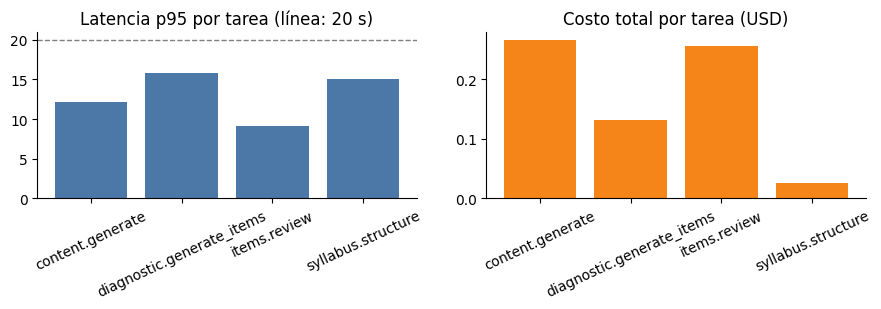

In [11]:
calls = frames["llm_calls"].copy()
live = calls[~calls["from_cache"].astype(bool)]            # una respuesta de caché no es una llamada al proveedor
lat = m.latency_percentiles([float(v) / 1000 for v in live["latency_ms"]])
invalid_pct = 100 * float((~calls["json_valid"].astype(bool)).mean())
record("Desempeño técnico", "Latencia p50 (s)", lat.p50, lat.n, "reportar", None)
record("Desempeño técnico", "Latencia p95 (s)", lat.p95, lat.n, "p95 < 20 s", lat.p95 < 20)
record("Desempeño técnico", "JSON inválido (%)", invalid_pct, len(calls), "< 2 %", invalid_pct < 2)

by_task = []
for task, g in live.groupby("task"):
    p = m.latency_percentiles([float(v) / 1000 for v in g["latency_ms"]])
    by_task.append({"task": task, "n": p.n, "p50 (s)": p.p50, "p95 (s)": p.p95,
                    "costo total (USD)": float(g["cost_usd"].sum())})
task_table = pd.DataFrame(by_task).round(3)
display(task_table)

per_enrollment = calls.dropna(subset=["enrollment_id"]).groupby("enrollment_id")["cost_usd"].sum()
if len(per_enrollment):
    record("Costo", "USD por inscripción (media)", per_enrollment.mean(), len(per_enrollment), "reportar", None)
record("Costo", "USD total de la cohorte", float(calls["cost_usd"].sum()), len(calls), "reportar", None)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
axes[0].bar(task_table["task"], task_table["p95 (s)"], color="#4c78a8")
axes[0].axhline(20, color="grey", ls="--", lw=1); axes[0].set_title("Latencia p95 por tarea (línea: 20 s)")
axes[0].tick_params(axis="x", rotation=25)
axes[1].bar(task_table["task"], task_table["costo total (USD)"], color="#f58518")
axes[1].set_title("Costo total por tarea (USD)"); axes[1].tick_params(axis="x", rotation=25)
plt.tight_layout(); plt.show()

## 9. Usabilidad: puntaje SUS

Fuente: `survey_responses.sus_items` (10 enteros de 1 a 5). Meta: SUS ≥ 68.

Respuestas SUS: 22 | media 70.6 | mediana 67.5


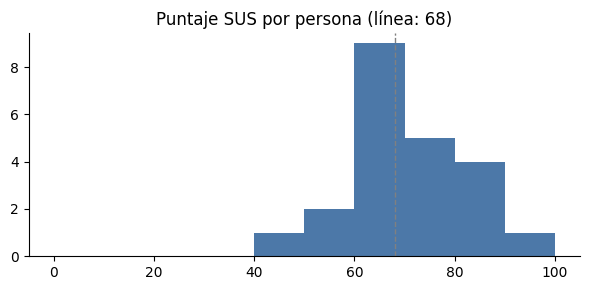

In [12]:
sv = frames["surveys"].copy()
sv["sus"] = [m.sus_score([int(v) for v in items]) for items in sv["sus_items"]]
sus_mean = float(sv["sus"].mean())
record("Usabilidad", "SUS medio", sus_mean, len(sv), "SUS ≥ 68", sus_mean >= 68)
print(f"Respuestas SUS: {len(sv)} | media {sus_mean:.1f} | mediana {sv['sus'].median():.1f}")
fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(sv["sus"], bins=np.arange(0, 105, 10), color="#4c78a8")
ax.axvline(68, color="grey", ls="--", lw=1); ax.set_title("Puntaje SUS por persona (línea: 68)")
plt.tight_layout(); plt.show()

## 10. Aprendizaje: ganancia de Hake y tamaño del efecto

Fuente: diagnóstico (pre) y evaluación final (post) con ítems equivalentes. La ganancia se calcula **por persona** y luego se promedia. Meta: g ≥ 0,3 (media). El d de Cohen compara las ganancias del grupo personalizado con las del grupo de ruta fija, con IC 95 % por bootstrap (semilla fija).

,brazo,n,g media,g DE
0,fixed,12,0.367,0.195
1,personalized,10,0.380,0.220


d de Cohen = 0.06  IC 95% [-0.73, 1.18]  (n = 10 vs 12)


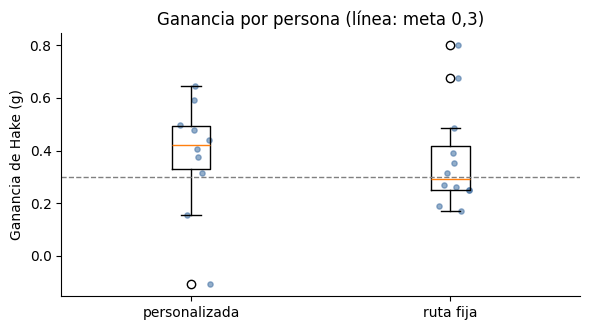

In [13]:
lg = frames["learning_gain"].dropna(subset=["pre_score", "post_score"]).copy()
lg["g"] = [m.hake_gain(float(a), float(b)) for a, b in zip(lg["pre_score"], lg["post_score"])]
lg = lg.dropna(subset=["g"])
overall_g, n_g = m.mean_hake_gain(list(zip(lg["pre_score"].astype(float), lg["post_score"].astype(float))))
record("Aprendizaje", "Ganancia de Hake media (todos)", overall_g, n_g, "g ≥ 0,3", overall_g >= 0.3)
arm_rows = []
for arm, g in lg.groupby("pilot_arm"):
    arm_rows.append({"brazo": arm, "n": len(g), "g media": g["g"].mean(), "g DE": g["g"].std()})
    record("Aprendizaje", f"Ganancia de Hake ({arm})", g["g"].mean(), len(g), "g ≥ 0,3", g["g"].mean() >= 0.3)
display(pd.DataFrame(arm_rows).round(3))

treat = [float(v) for v in lg.loc[lg["pilot_arm"] == "personalized", "g"]]
ctrl = [float(v) for v in lg.loc[lg["pilot_arm"] == "fixed", "g"]]
if len(treat) >= 2 and len(ctrl) >= 2:
    eff = m.cohens_d_with_ci(treat, ctrl, n_bootstrap=N_BOOTSTRAP, seed=SEED)
    record("Aprendizaje", "d de Cohen (personalizada - ruta fija)", eff.d, len(treat) + len(ctrl), "reportar con IC 95 %", None)
    print(f"d de Cohen = {eff.d:.2f}  IC {eff.confidence:.0%} [{eff.ci_low:.2f}, {eff.ci_high:.2f}]  (n = {len(treat)} vs {len(ctrl)})")
else:
    print("d de Cohen no calculable: se necesitan al menos 2 personas por brazo.")
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.boxplot([treat, ctrl], tick_labels=["personalizada", "ruta fija"])
for i, vals in enumerate([treat, ctrl], start=1):
    ax.scatter(np.random.default_rng(SEED).normal(i, 0.04, len(vals)), vals, color="#4c78a8", alpha=0.6, s=14)
ax.axhline(0.3, color="grey", ls="--", lw=1); ax.set_ylabel("Ganancia de Hake (g)")
ax.set_title("Ganancia por persona (línea: meta 0,3)")
plt.tight_layout(); plt.show()

## 11. Recorrido de la ruta: dominio, primer intento, intentos, finalización y abandono

Fuente: `path_steps`, `enrollments` y `badges`. Metas: aprobación al primer intento entre 60 % y 85 %, intentos por tema ≤ 1,8, finalización ≥ 60 %. Dominio y abandono se reportan por tema.

,dominio (%),nivel diagnóstico medio,abandonos,intentos medios
topic_id,,,,
t_conditionals,70.83,0.60,1.0,1.76
t_data_structures,70.83,0.59,0.0,1.64
t_functions,62.50,0.62,0.0,1.65
t_loops,66.67,0.58,1.0,1.73
t_variables,70.83,0.59,0.0,1.83


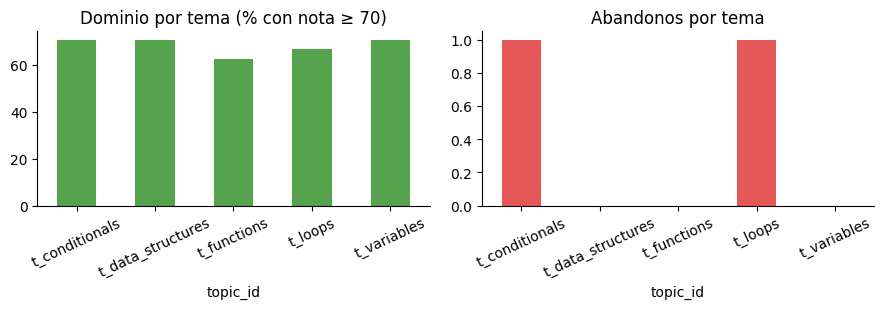

In [14]:
attempted = path_steps[(path_steps["attempts_used"] > 0) & path_steps["first_attempt_passed"].notna()]
first_rate = 100 * float(attempted["first_attempt_passed"].astype(bool).mean())
record("Estudiantes", "Aprobación al primer intento (%)", first_rate, len(attempted), "60 % a 85 %", 60 <= first_rate <= 85)
passed_steps = attempted[attempted["passed"].astype(bool)]
mean_attempts = float(passed_steps["attempts_used"].mean())
record("Estudiantes", "Intentos hasta aprobar (media)", mean_attempts, len(passed_steps), "≤ 1,8", mean_attempts <= 1.8)

completion = 100 * float((enrollments["status"] == "completed").mean())
badge_rate = 100 * float(enrollments["badge_earned"].astype(bool).mean())
record("Estudiantes", "Finalización (%)", completion, len(enrollments), "≥ 60 %", completion >= 60)
record("Estudiantes", "Con badge (%)", badge_rate, len(enrollments), "reportar", None)

# Abandono: en una inscripción abandonada, el primer tema sin terminar (pendiente, en curso, bloqueado o en pausa).
unfinished = path_steps.merge(enrollments[["enrollment_id", "status"]].rename(columns={"status": "enrollment_status"}), on="enrollment_id")
unfinished = unfinished[(unfinished["enrollment_status"] == "abandoned")
                        & unfinished["status"].isin(["pending", "in_progress", "blocked", "on_hold"])]
left_at = unfinished.sort_values("position").groupby("enrollment_id").first()["topic_id"].value_counts()
path_steps = path_steps.assign(abandoned_here=path_steps["topic_id"].map(left_at).fillna(0))

by_topic = path_steps.groupby("topic_id").apply(lambda g: pd.Series({
    "dominio (%)": 100 * float((g["best_score"].fillna(0) >= PASS_SCORE).mean()),
    "nivel diagnóstico medio": float(g["diagnostic_level"].mean()),
    "abandonos": int(g["abandoned_here"].iloc[0]),
    "intentos medios": float(g.loc[g["attempts_used"] > 0, "attempts_used"].mean()),
}), include_groups=False).round(2)
display(by_topic)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
by_topic["dominio (%)"].plot.bar(ax=axes[0], color="#54a24b", rot=25); axes[0].set_title("Dominio por tema (% con nota ≥ 70)")
by_topic["abandonos"].plot.bar(ax=axes[1], color="#e45756", rot=25); axes[1].set_title("Abandonos por tema")
plt.tight_layout(); plt.show()

## 12. Eficiencia de la personalización y equidad

Eficiencia: temas omitidos (`skipped_mastered`) y minutos ahorrados frente a la ruta fija, **sin pérdida de aprendizaje** (ver la ganancia de la sección 10). Equidad: tasa de aprobación al primer intento por nivel de inglés y por tener o no hoja de vida (informe de recomendadores, sección 4.2 del plan).

,brazo,personas,temas omitidos por persona,minutos ahorrados por persona
0,fixed,12,0.00,0.00
1,personalized,12,0.42,15.83


,n,aprobación 1.er intento (%)
english_level,,
A2,30.0,46.7
B1,39.0,53.8
B2,17.0,82.4
C1,22.0,27.3


,n,aprobación 1.er intento (%)
has_resume,,
False,31.0,48.4
True,77.0,51.9


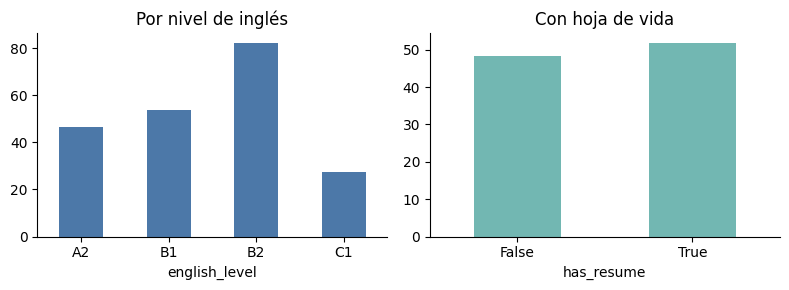

In [15]:
per_arm = path_steps.merge(enrollments[["enrollment_id", "pilot_arm"]], on="enrollment_id")
skipped = per_arm[per_arm["inclusion_reason"] == "skipped_mastered"]
eff_rows = []
for arm, g in per_arm.groupby("pilot_arm"):
    people = g["enrollment_id"].nunique()
    sk = g[g["inclusion_reason"] == "skipped_mastered"]
    eff_rows.append({"brazo": arm, "personas": people,
                     "temas omitidos por persona": len(sk) / people,
                     "minutos ahorrados por persona": float(sk["estimated_minutes"].sum()) / people})
display(pd.DataFrame(eff_rows).round(2))
if len(skipped):
    record("Eficiencia", "Minutos ahorrados por persona (personalizada)",
           float(skipped["estimated_minutes"].sum()) / per_arm.loc[per_arm["pilot_arm"] == "personalized", "enrollment_id"].nunique(),
           per_arm.loc[per_arm["pilot_arm"] == "personalized", "enrollment_id"].nunique(), "reportar", None)

eq = attempted.merge(enrollments[["enrollment_id", "english_level", "has_resume"]], on="enrollment_id")
equity = {}
for col in ("english_level", "has_resume"):
    equity[col] = eq.groupby(col).apply(lambda g: pd.Series({
        "n": len(g), "aprobación 1.er intento (%)": 100 * float(g["first_attempt_passed"].astype(bool).mean())}),
        include_groups=False).round(1)
    display(equity[col])
fig, axes = plt.subplots(1, 2, figsize=(8, 3))
equity["english_level"]["aprobación 1.er intento (%)"].plot.bar(ax=axes[0], rot=0, color="#4c78a8"); axes[0].set_title("Por nivel de inglés")
equity["has_resume"]["aprobación 1.er intento (%)"].plot.bar(ax=axes[1], rot=0, color="#72b7b2"); axes[1].set_title("Con hoja de vida")
plt.tight_layout(); plt.show()

## 13. Percepción (Likert 1 a 5)

Fuente: `survey_responses.likert`. Meta: media ≥ 4.

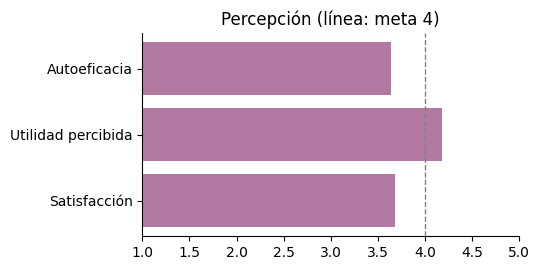

In [16]:
likert_cols = {"likert_satisfaction": "Satisfacción", "likert_usefulness": "Utilidad percibida", "likert_self_efficacy": "Autoeficacia"}
lk = {label: float(sv[col].astype(float).mean()) for col, label in likert_cols.items()}
for label, value in lk.items():
    record("Percepción", f"Likert: {label}", value, len(sv), "media ≥ 4", value >= 4)
fig, ax = plt.subplots(figsize=(5.5, 2.8))
ax.barh(list(lk), list(lk.values()), color="#b279a2"); ax.axvline(4, color="grey", ls="--", lw=1)
ax.set_xlim(1, 5); ax.set_title("Percepción (línea: meta 4)")
plt.tight_layout(); plt.show()

## 14. Tablero final

Cada fila es una métrica del brief con su meta. `reportar` significa que el brief solo pide reportar el valor. **Tiempo en tarea** (`interaction_events`) no se calcula en este cuaderno: depende del contrato de eventos de la interfaz y queda pendiente (ver `docs/evaluation/metrics.md`).

,dimension,metric,value,n,goal,met
0,Syllabus,F1 de temas,0.833,6,"F1 ≥ 0,85",no
1,Syllabus,F1 de prerrequisitos,0.909,5,"F1 ≥ 0,85",sí
2,Calidad de preguntas,% de preguntas válidas,71.250,80,≥ 80 %,no
3,Calidad de preguntas,κ de Cohen (veredicto),0.726,80,"κ ≥ 0,6",sí
4,Psicometría,"% de ítems con discriminación ≥ 0,2",45.833,24,"discriminación ≥ 0,2",reportar
5,Psicometría,Discriminación mediana,0.094,24,"≥ 0,2",no
6,Texto generado (RAG),Fidelidad media,0.887,40,"≥ 0,8",sí
7,Recomendación de videos,Precision@3 (media por tema),0.800,5,"P@3 ≥ 0,7",sí
8,Recomendación de videos,nDCG@3 (media por tema),0.912,5,reportar,reportar
9,Calificación automática,QWK (muestra aleatoria),0.846,48,"QWK ≥ 0,6",sí


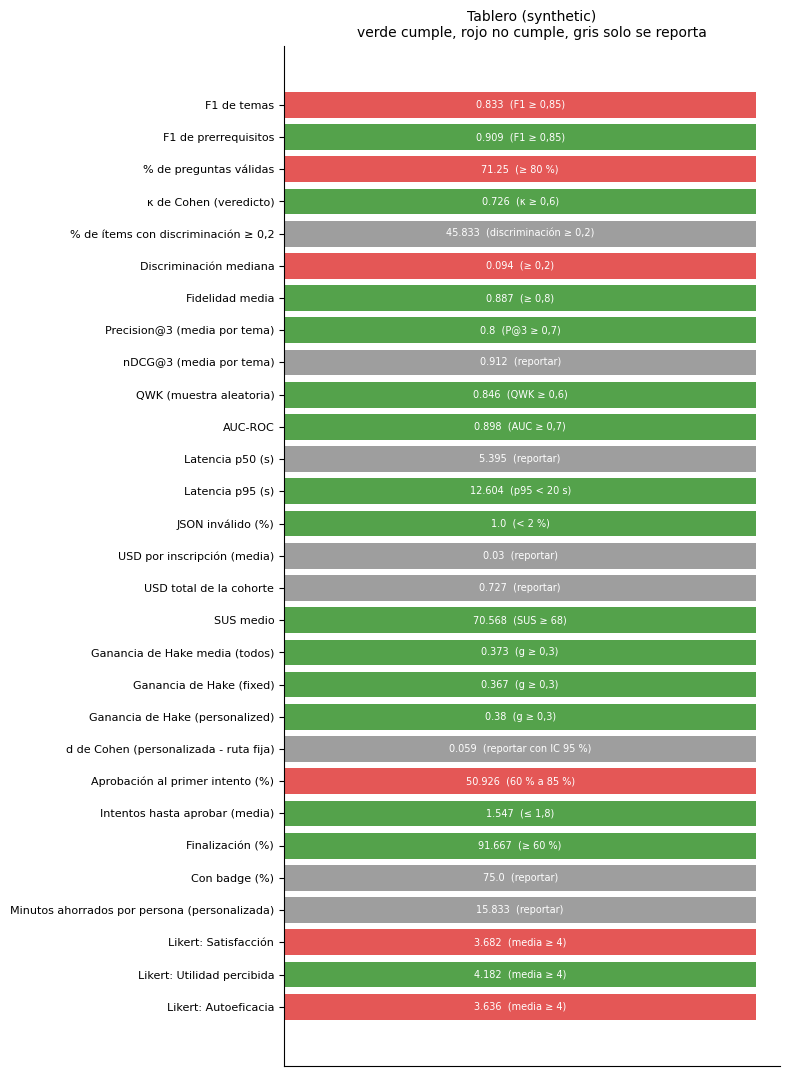

Modo: synthetic | métricas calculadas: 29


In [17]:
summary = pd.DataFrame(scorecard)
display(summary)
fig, ax = plt.subplots(figsize=(8, 0.34 * len(summary) + 1))
colors = {"sí": "#54a24b", "no": "#e45756", "reportar": "#9e9e9e"}
ax.barh(range(len(summary)), [1] * len(summary), color=[colors[v] for v in summary["met"]])
ax.set_yticks(range(len(summary)))
ax.set_yticklabels(summary["metric"], fontsize=8); ax.invert_yaxis()
for i, row in summary.iterrows():
    ax.text(0.5, i, f"{row['value']}  ({row['goal']})", ha="center", va="center", color="white", fontsize=7)
ax.set_xticks([]); ax.set_title(f"Tablero ({MODE})\nverde cumple, rojo no cumple, gris solo se reporta", fontsize=10)
plt.tight_layout(); plt.show()
print("Modo:", MODE, "| métricas calculadas:", len(summary))